# AnalystLab Africa — Track B: Data Science
## Airbnb Pricing, Location and Listing Characteristics Investigation

**Environment:** Databricks  
**Primary libraries:** pandas, NumPy, Matplotlib, Seaborn, SciPy  
**Large-table processing:** Spark

### Project focus
Primary research question: **How does advertised listing price vary across room types within each city?**

Supporting questions:
1. Within each city, is accommodation capacity associated with advertised listing price?
2. Is listing-level review activity associated with the available aggregate listing rating?
3. How do listing and review activity patterns differ across cities and room types?

> Important: Prices are expressed in the local currencies associated with each market. The source Listings table has no currency column. This notebook therefore analyses prices **within each city** and does not rank cities by raw price.

## 1. Setup and data ingestion


In [0]:

# Import libraries required for the analysis.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy import stats

# Set default plot appearance using Matplotlib.
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.size"] = 10
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 11

# Display pandas dataframes clearly.
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_rows", 100)

print("Libraries imported successfully!")


Libraries imported successfully!


In [0]:


from scipy import stats
from pyspark.sql import functions as F
from pyspark.sql.types import *
from IPython.display import display

# Make notebook output easier to read and plots consistent.
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_rows", 100)
#sns.set_theme(style="whitegrid", context="notebook")

# Choose the Databricks table ingestion route shown in the supplied screenshots.
USE_DATABRICKS_TABLES = True

if USE_DATABRICKS_TABLES:
    # Read the registered Databricks tables.
    sdf_listings = spark.read.table("workspace.airbnb.listings")
    sdf_reviews = spark.read.table("workspace.airbnb.reviews")

# Keep the Spark DataFrames available for scalable processing.
print("Listings rows:", sdf_listings.count())
print("Reviews rows:", sdf_reviews.count())
print("Listings columns:", len(sdf_listings.columns))
print("Reviews columns:", len(sdf_reviews.columns))

# Convert the listings table to pandas. It contains approximately 280K rows.
df_listings = sdf_listings.toPandas()

# Keep the Reviews dataset in Spark. Do not convert all review rows to pandas.
print("Listings pandas shape:", df_listings.shape)
display(sdf_listings.limit(5))
display(sdf_reviews.limit(5))

Listings rows: 279712
Reviews rows: 5373143
Listings columns: 33
Reviews columns: 4
Listings pandas shape: (279712, 33)


DataFrame[listing_id: bigint, name: string, host_id: bigint, host_since: date, host_location: string, host_response_time: string, host_response_rate: double, host_acceptance_rate: double, host_is_superhost: string, host_total_listings_count: bigint, host_has_profile_pic: string, host_identity_verified: string, neighbourhood: string, district: string, city: string, latitude: double, longitude: double, property_type: string, room_type: string, accommodates: bigint, bedrooms: bigint, amenities: string, price: bigint, minimum_nights: bigint, maximum_nights: bigint, review_scores_rating: bigint, review_scores_accuracy: bigint, review_scores_cleanliness: bigint, review_scores_checkin: bigint, review_scores_communication: bigint, review_scores_location: bigint, review_scores_value: bigint, instant_bookable: string]

DataFrame[listing_id: bigint, review_id: bigint, date: date, reviewer_id: bigint]

## 2. Dataset structure and data dictionary review

The supplied Listings dictionary defines 33 fields, including listing/host identifiers, city, neighbourhood, district, price, room type, property type, capacity, bedrooms and listing-level review scores.

The Reviews dictionary defines four fields:
- `listing_id`: Listing ID
- `review_id`: Review ID
- `date`: Review date
- `reviewer_id`: Reviewer ID

The Reviews table contains review identifiers and dates, not review text or individual review scores. We can measure review volume and timing, but cannot perform text sentiment analysis.

In [0]:
# Inspect field names, data types and a sample of the listings data.
print("Listings shape:", df_listings.shape)
display(df_listings.head())

# Inspect pandas data types.
display(df_listings.dtypes.astype(str).rename("data_type").to_frame())

# Confirm the four review fields and their Spark data types.
print("Reviews schema:")
sdf_reviews.printSchema()

Listings shape: (279712, 33)


,listing_id,name,host_id,host_since,host_location,host_response_time,host_response_rate,host_acceptance_rate,host_is_superhost,host_total_listings_count,host_has_profile_pic,host_identity_verified,neighbourhood,district,city,latitude,longitude,property_type,room_type,accommodates,bedrooms,amenities,price,minimum_nights,maximum_nights,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,instant_bookable
0,35343471,Habitacion Privada en sur cdmx con PROTOCOLO C...,206251954,2018-07-30,"Mexico City, Mexico City, Mexico",within a day,0.85,0.89,t,3.0,t,t,A�lvaro Obregon,None,Mexico City,19.34215,-99.18912,Private room in apartment,Private room,2,1.0,"[""TV"", ""Dedicated workspace"", ""Shower gel"", ""F...",399,2,1125,97.0,10.0,10.0,10.0,10.0,10.0,10.0,t
1,37655338,Habitacion super centrica,279256438,2019-07-25,MX,a few days or more,0.00,0.63,f,1.0,t,f,Cuauhtemoc,None,Mexico City,19.43733,-99.13806,Private room in apartment,Private room,2,1.0,"[""Washer"", ""TV"", ""Luggage dropoff allowed"", ""S...",200,2,1125,94.0,10.0,9.0,10.0,10.0,10.0,9.0,t
2,41180430,Habitacion Privada con BaÃ±o; 2 camas individu...,219335209,2018-10-07,"Mexico City, Mexico City, Mexico",within a day,0.50,1.00,f,0.0,t,t,Miguel Hidalgo,None,Mexico City,19.43655,-99.20736,Private room in apartment,Private room,2,1.0,"[""Dedicated workspace"", ""Dryer"", ""Shampoo"", ""E...",1025,2,1125,100.0,10.0,10.0,10.0,10.0,10.0,10.0,t
3,45768877,"Habitacion amplia y comoda, excelente ubicacion!",368143920,2020-09-18,MX,a few days or more,0.30,1.00,f,0.0,t,t,Benito Juarez,None,Mexico City,19.38270,-99.15745,Private room in apartment,Private room,2,1.0,"[""TV"", ""Dedicated workspace"", ""Dryer"", ""Free p...",340,2,1125,92.0,10.0,9.0,10.0,10.0,10.0,10.0,t
4,47079788,ROOM for RENT- Contemporary- In the heart CONDESA,52517534,2015-12-28,"Mexico City, Mexico City, Mexico",within a few hours,0.89,0.80,f,0.0,t,f,Cuauhtemoc,None,Mexico City,19.40537,-99.16898,Private room in apartment,Private room,2,1.0,"[""Washer"", ""Dedicated workspace"", ""Shampoo"", ""...",516,2,1125,80.0,10.0,8.0,10.0,10.0,10.0,10.0,t


,data_type
listing_id,int64
name,object
host_id,int64
host_since,object
host_location,object
host_response_time,object
host_response_rate,float64
host_acceptance_rate,float64
host_is_superhost,object
host_total_listings_count,float64


Reviews schema:
root
 |-- listing_id: long (nullable = true)
 |-- review_id: long (nullable = true)
 |-- date: date (nullable = true)
 |-- reviewer_id: long (nullable = true)



## 3. Data quality assessment and preparation

We preserve the original dataframes and create working copies. Key checks include primary-key uniqueness, missingness, invalid prices, and the listing-to-review relationship.

The source file is known to contain 160 repeated `review_id` values. Do not delete those rows automatically: inspect the repeated identifiers and retain the composite `(listing_id, review_id)` as the record-level uniqueness check.

In [0]:
# Create a working copy; preserve df_listings as the ingested source.
df = df_listings.copy()

# Convert numeric fields explicitly so unexpected strings become missing values.
numeric_cols = [
    "price", "accommodates", "bedrooms", "minimum_nights",
    "maximum_nights", "review_scores_rating",
    "review_scores_accuracy", "review_scores_cleanliness",
    "review_scores_checkin", "review_scores_communication",
    "review_scores_location", "review_scores_value",
    "host_total_listings_count"
]
for col in numeric_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

# Parse host_since as a date where available.
df["host_since"] = pd.to_datetime(df["host_since"], errors="coerce")

# Missing-value profile.
missing_summary = (
    df.isna().sum()
      .to_frame("missing_count")
      .assign(missing_pct=lambda x: 100 * x["missing_count"] / len(df))
      .sort_values("missing_pct", ascending=False)
)
display(missing_summary)

# Primary-key check: listing_id should identify one listing record.
print("Duplicate listing_id rows:", df["listing_id"].duplicated().sum())
print("Unique listing IDs:", df["listing_id"].nunique())

# Check zero, negative and missing advertised prices.
invalid_price_mask = df["price"].isna() | (df["price"] <= 0)
print("Missing or non-positive prices:", int(invalid_price_mask.sum()))
print("Zero prices:", int((df["price"] == 0).sum()))
print("Negative prices:", int((df["price"] < 0).sum()))

# Review the extreme values before deciding how to treat them.
display(df["price"].describe(percentiles=[.01, .25, .50, .75, .90, .95, .99]).to_frame())

,missing_count,missing_pct
district,242700,86.767818
host_response_time,128782,46.040928
host_response_rate,128782,46.040928
host_acceptance_rate,113087,40.429799
review_scores_value,91785,32.814109
review_scores_location,91775,32.810534
review_scores_checkin,91771,32.809104
review_scores_accuracy,91713,32.788368
review_scores_communication,91687,32.779073
review_scores_cleanliness,91665,32.771208


Duplicate listing_id rows: 0
Unique listing IDs: 279712
Missing or non-positive prices: 113
Zero prices: 113
Negative prices: 0


,price
count,279712.000000
mean,608.792737
std,3441.826611
min,0.000000
1%,25.000000
25%,75.000000
50%,150.000000
75%,474.000000
90%,1200.000000
95%,2000.000000


In [0]:
# Count review rows and investigate repeated review_id values with Spark.
# The groupBy avoids collecting the full Reviews table into pandas.
review_id_frequency = (
    sdf_reviews.groupBy("review_id")
    .agg(F.count("*").alias("record_count"))
)

repeated_review_ids = review_id_frequency.filter(F.col("record_count") > 1)
print("Number of review_id values appearing more than once:",
      repeated_review_ids.count())
display(repeated_review_ids.orderBy(F.desc("record_count")).limit(30))

# Check whether the composite (listing_id, review_id) is unique.
duplicate_composite_count = (
    sdf_reviews.groupBy("listing_id", "review_id")
    .count()
    .filter(F.col("count") > 1)
    .count()
)
print("Duplicate (listing_id, review_id) combinations:", duplicate_composite_count)

# Validate that every review listing_id matches a listing_id.
listing_keys = sdf_listings.select("listing_id").distinct()
review_keys = sdf_reviews.select("listing_id").distinct()
unmatched_review_listing_ids = review_keys.join(
    listing_keys, on="listing_id", how="left_anti"
)
print("Review listing IDs without a matching listing:", unmatched_review_listing_ids.count())

# Count review records per listing in Spark, then collect only the aggregate.
review_counts_spark = (
    sdf_reviews.groupBy("listing_id")
    .agg(F.count("*").alias("review_count"))
)
review_counts = review_counts_spark.toPandas()
display(review_counts.head())

Number of review_id values appearing more than once: 160


DataFrame[review_id: bigint, record_count: bigint]

Duplicate (listing_id, review_id) combinations: 0
Review listing IDs without a matching listing: 0


,listing_id,review_count
0,10709634,41
1,12051150,82
2,12309502,139
3,12385180,64
4,12727055,127


In [0]:
# Add review counts to the listings working dataframe.
df = df.merge(review_counts, on="listing_id", how="left")
df["review_count"] = df["review_count"].fillna(0).astype("int64")

# Record whether a listing has at least one review record.
df["has_review_record"] = df["review_count"] > 0

# Keep valid positive prices for price-based analyses.
# Do not automatically delete high prices: inspect them and use robust summaries.
df["price_valid"] = df["price"].notna() & (df["price"] > 0)
df_price = df.loc[df["price_valid"]].copy()

print("All listing rows:", len(df))
print("Listings with valid positive price:", len(df_price))
print("Listings with no review rows:", int((df["review_count"] == 0).sum()))
display(df[["listing_id", "city", "price", "room_type", "review_count"]].head())

All listing rows: 279712
Listings with valid positive price: 279599
Listings with no review rows: 86156


,listing_id,city,price,room_type,review_count
0,35343471,Mexico City,399,Private room,42
1,37655338,Mexico City,200,Private room,34
2,41180430,Mexico City,1025,Private room,5
3,45768877,Mexico City,340,Private room,5
4,47079788,Mexico City,516,Private room,1


## 4. Research questions and hypotheses

### Primary research question
How does advertised listing price vary across room types within each city?

**H1 — Room type and advertised price**  
- Null hypothesis (H0): Within a city, advertised price distributions are the same across room types.
- Alternative hypothesis (H1): At least one room type has a different advertised price distribution within that city.
- Test: Kruskal–Wallis H test, conducted separately for each city. This non-parametric test is suitable for skewed price distributions and multiple independent groups. Only groups with at least 30 observations are included; group sizes must be reported.

### Supporting question 1
Is accommodation capacity associated with advertised price within each city?

**H2**  
- H0: Spearman rank correlation between `accommodates` and `price` is zero within a city.
- H1: The correlation is not zero.
- Test: Spearman rank correlation, separately by city.

### Supporting question 2
Is review activity associated with the available aggregate listing rating?

**H3**  
- H0: Spearman rank correlation between listing review count and `review_scores_rating` is zero.
- H1: The correlation is not zero.
- Test: Spearman rank correlation on listings with an available rating.



In [0]:
# Descriptive listing distribution by city.
city_listing_counts = (
    df.groupby("city")["listing_id"]
      .nunique()
      .sort_values(ascending=False)
      .rename("listing_count")
      .reset_index()
)
display(city_listing_counts)

# City-level price summaries. These are within-city statistics only.
# Do not compare the raw price amounts across cities because currencies differ.
city_price_summary = (
    df_price.groupby("city")["price"]
    .agg(
        listing_count="count",
        median_price="median",
        mean_price="mean",
        q1=lambda x: x.quantile(0.25),
        q3=lambda x: x.quantile(0.75),
        p95=lambda x: x.quantile(0.95)
    )
    .sort_index()
)
display(city_price_summary.round(2))

,city,listing_count
0,Paris,64690
1,New York,37012
2,Sydney,33630
3,Rome,27647
4,Rio de Janeiro,26615
5,Istanbul,24519
6,Mexico City,20065
7,Bangkok,19361
8,Cape Town,19086
9,Hong Kong,7087


,listing_count,median_price,mean_price,q1,q3,p95
city,,,,,,
Bangkok,19360,1100.0,2078.39,700.0,1900.0,5286.70
Cape Town,19086,1069.0,2405.12,650.0,2200.0,7867.50
Hong Kong,7087,386.0,746.17,248.0,700.0,1938.00
Istanbul,24517,252.0,532.60,150.0,449.0,1185.00
Mexico City,20058,664.0,1149.65,392.0,1124.0,2861.15
New York,36984,99.0,142.95,60.0,151.0,349.00
Paris,64628,80.0,113.20,59.0,120.0,270.00
Rio de Janeiro,26608,280.0,742.78,157.0,550.0,1957.00
Rome,27641,65.0,105.13,45.0,99.0,240.00


## 5. Exploratory Data Analysis (EDA)

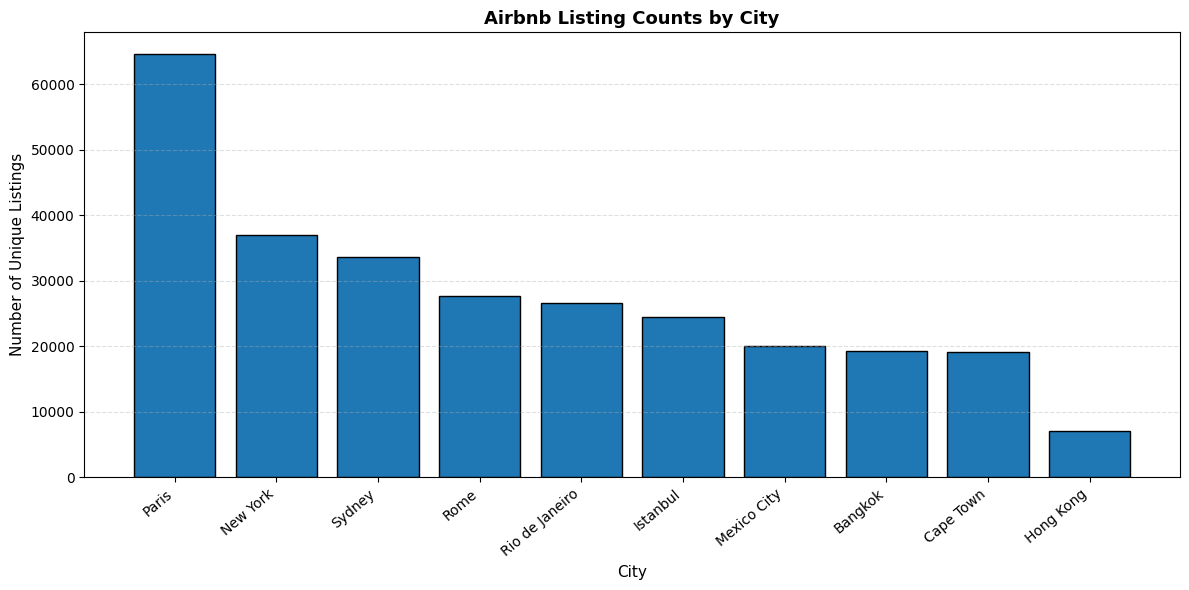

In [0]:

# VISUALISATION 1: Number of listings by city.

# Create the figure.
plt.figure(figsize=(12, 6))

# Create a bar chart using Matplotlib.
plt.bar(
    city_listing_counts["city"],
    city_listing_counts["listing_count"],
    edgecolor="black"
)

# Add chart title and axis labels.
plt.title("Airbnb Listing Counts by City", fontweight="bold")
plt.xlabel("City")
plt.ylabel("Number of Unique Listings")

# Rotate city names for readability.
plt.xticks(rotation=40, ha="right")

# Add gridlines to improve readability.
plt.grid(axis="y", linestyle="--", alpha=0.4)

# Adjust spacing and display.
plt.tight_layout()
plt.show()


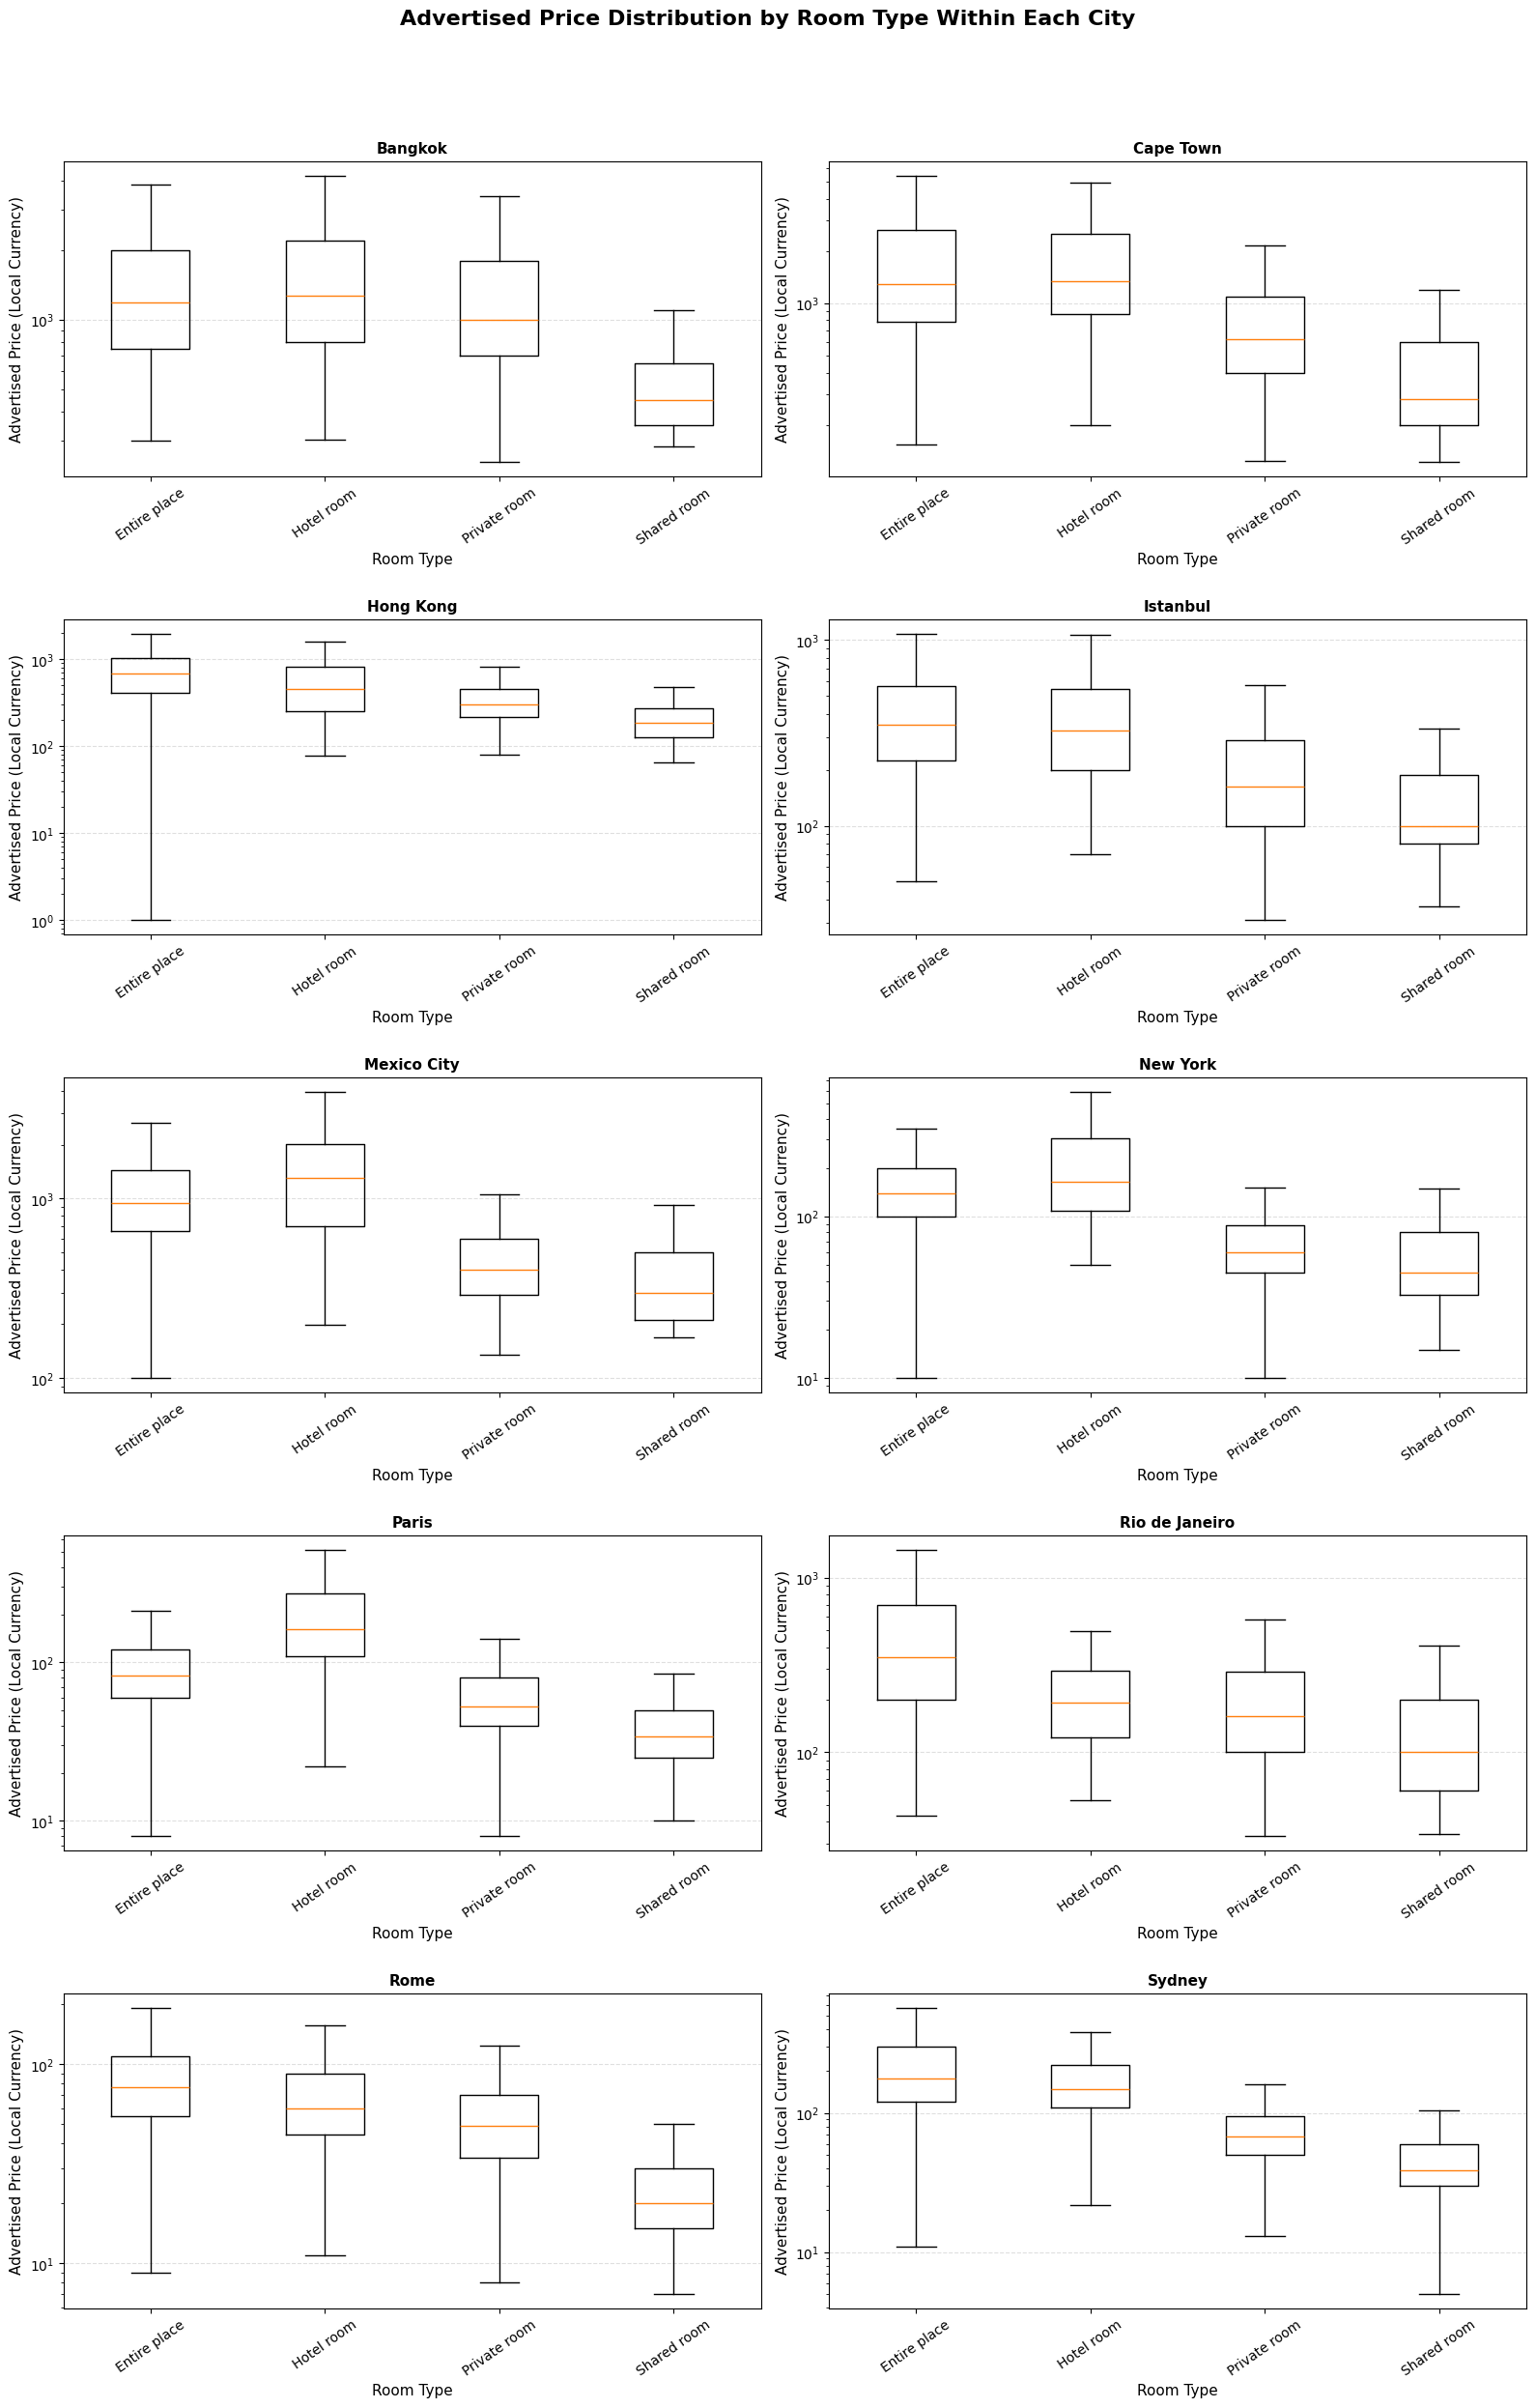

In [0]:

# ============================================================
# VISUALISATION 2: Price Distribution by Room Type and City
# ============================================================

# Identify all available cities.
cities = sorted(df_price["city"].dropna().unique())

# Create a grid with two columns.
n_cities = len(cities)
n_cols = 2
n_rows = int(np.ceil(n_cities / n_cols))

# Create the figure and subplot axes FIRST.
fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(16, 5 * n_rows)
)

# Convert axes into a one-dimensional array.
axes = np.array(axes).flatten()

# Loop through each city.
for i, city in enumerate(cities):

    # Filter listings belonging to the current city.
    city_data = df_price[df_price["city"] == city]

    # Identify available room types.
    room_types = sorted(
        city_data["room_type"].dropna().unique()
    )

    # Prepare price data for each room type.
    price_groups = [
        city_data.loc[
            city_data["room_type"] == room,
            "price"
        ].dropna().values
        for room in room_types
    ]

    # Draw the boxplot.
    axes[i].boxplot(
        price_groups,
        tick_labels=room_types,
        showfliers=False
    )

    # Apply logarithmic scale to handle skewed prices.
    axes[i].set_yscale("log")

    # Add individual city titles and axis labels.
    axes[i].set_title(
        city,
        fontsize=11,
        fontweight="bold"
    )

    axes[i].set_xlabel("Room Type")
    axes[i].set_ylabel(
        "Advertised Price (Local Currency)"
    )

    # Rotate room type labels.
    axes[i].tick_params(
        axis="x",
        rotation=35
    )

    # Add horizontal gridlines.
    axes[i].grid(
        axis="y",
        linestyle="--",
        alpha=0.4
    )

# Hide unused subplot spaces.
for j in range(n_cities, len(axes)):
    axes[j].set_visible(False)

# ------------------------------------------------------------
# ADD THE OVERALL TITLE AFTER CREATING ALL SUBPLOTS.
# ------------------------------------------------------------

fig.suptitle(
    "Advertised Price Distribution by Room Type Within Each City",
    fontsize=16,
    fontweight="bold",
    y=0.995
)

# Adjust spacing to prevent overlapping titles.
fig.tight_layout(
    rect=[0, 0, 1, 0.96],
    h_pad=2.5
)

# Save the chart at high resolution for your portfolio.
fig.savefig(
    "airbnb_price_distribution_by_room_type.png",
    dpi=300,
    bbox_inches="tight"
)

# Display the final visualisation.
plt.show()


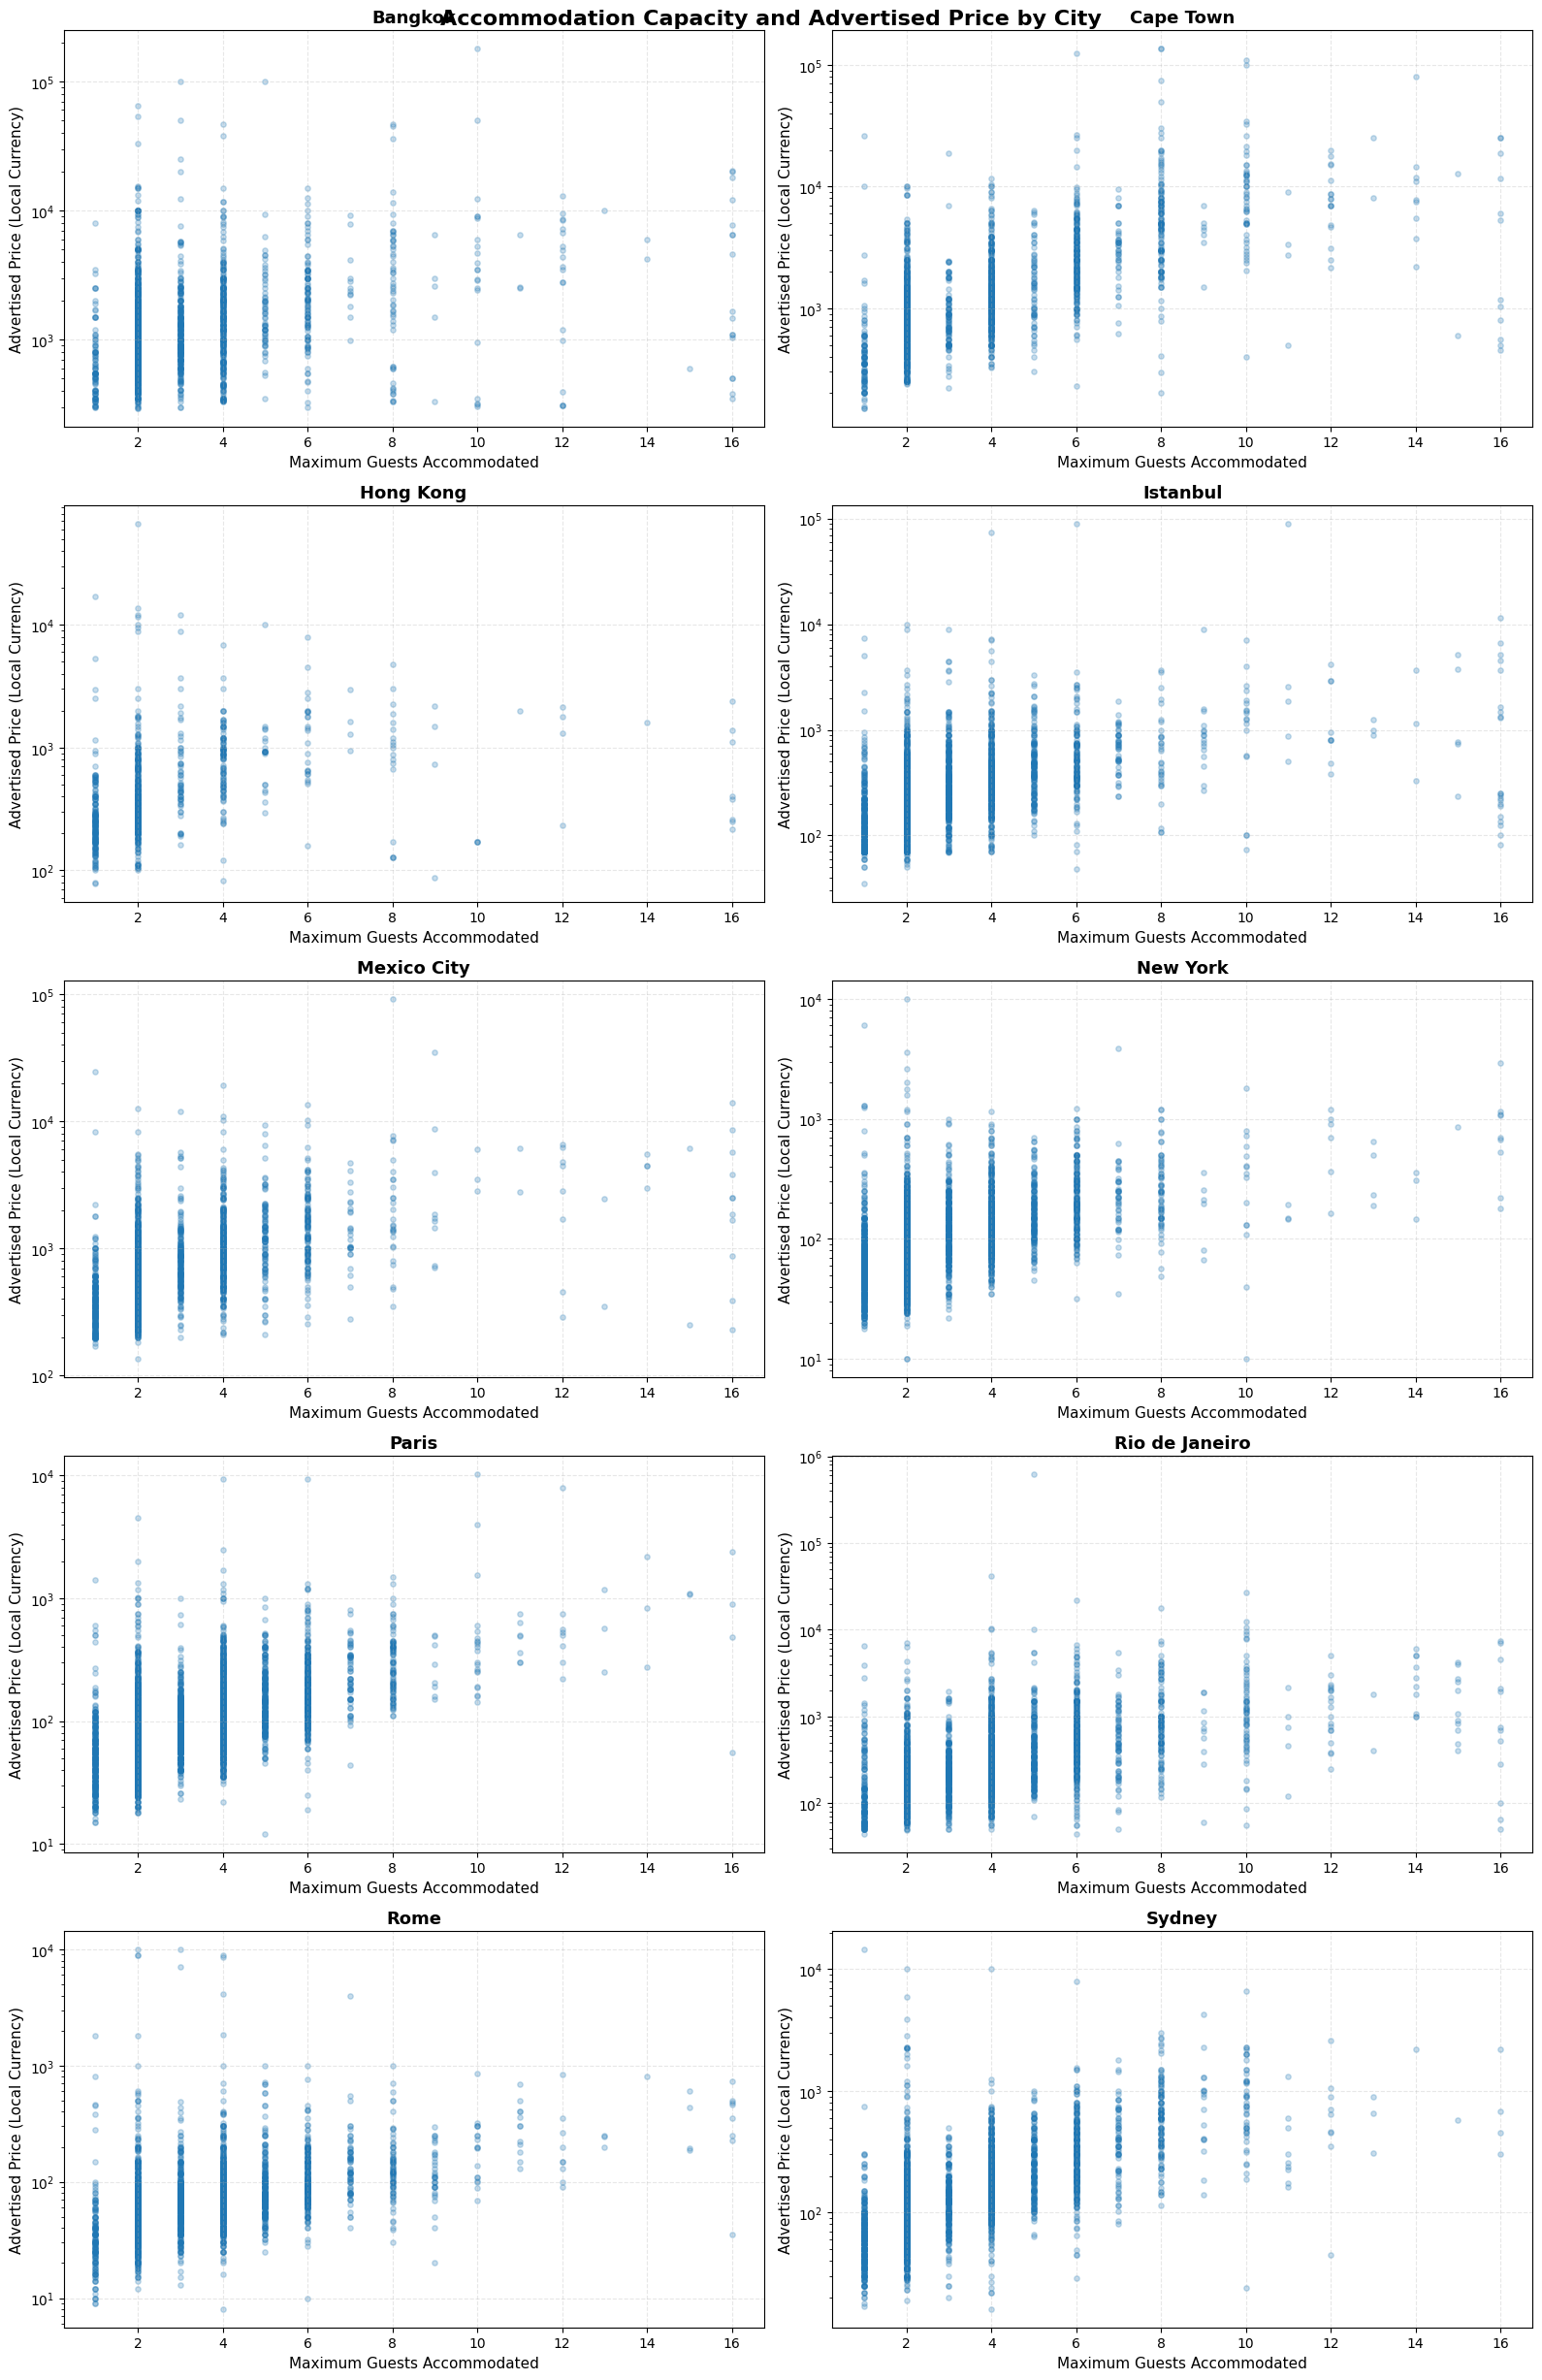

In [0]:

# VISUALISATION 4: Accommodation capacity versus advertised price.

# Remove rows with missing capacity or price.
plot_data = df_price.dropna(
    subset=["accommodates", "price"]
).copy()

# Use a sample of up to 30,000 listings for faster plotting.
plot_sample = plot_data.sample(
    n=min(30000, len(plot_data)),
    random_state=42
)

# Identify the available cities.
cities = sorted(plot_sample["city"].dropna().unique())

# Create a subplot grid.
n_cols = 2
n_rows = int(np.ceil(len(cities) / n_cols))

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(16, 5 * n_rows)
)

axes = np.array(axes).flatten()

# Create one scatter plot per city.
for i, city in enumerate(cities):

    city_data = plot_sample[
        plot_sample["city"] == city
    ]

    axes[i].scatter(
        city_data["accommodates"],
        city_data["price"],
        alpha=0.25,
        s=15
    )

    # Use logarithmic scale to handle skewed prices.
    axes[i].set_yscale("log")

    axes[i].set_title(city, fontweight="bold")
    axes[i].set_xlabel("Maximum Guests Accommodated")
    axes[i].set_ylabel("Advertised Price (Local Currency)")

    axes[i].grid(
        linestyle="--",
        alpha=0.3
    )

# Hide unused subplot spaces.
for j in range(len(cities), len(axes)):
    axes[j].set_visible(False)

fig.suptitle(
    "Accommodation Capacity and Advertised Price by City",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


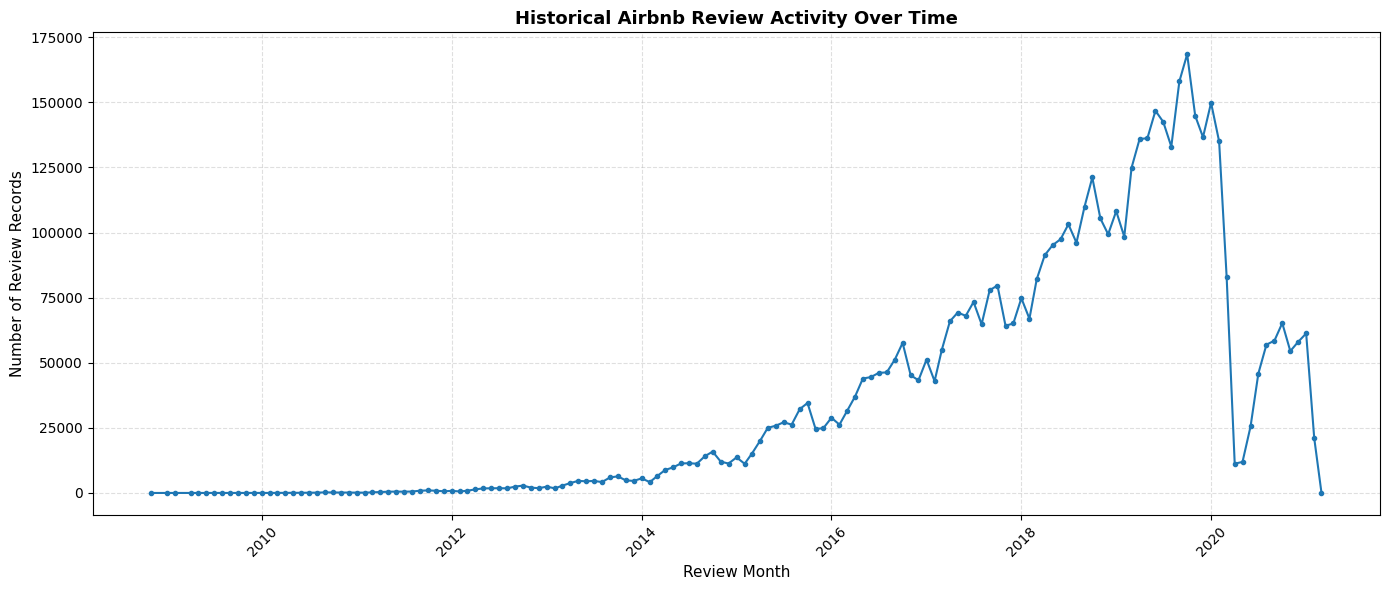

In [0]:

# VISUALISATION 5: Historical review activity over time.

# Import Spark functions.
from pyspark.sql import functions as F

# Convert review dates and aggregate records by month.
monthly_reviews_spark = (
    sdf_reviews
    .withColumn(
        "review_date",
        F.to_date("date")
    )
    .withColumn(
        "review_month",
        F.date_trunc("month", F.col("review_date"))
    )
    .groupBy("review_month")
    .agg(
        F.count("*").alias("review_records")
    )
    .orderBy("review_month")
)

# Convert the aggregated results to pandas.
monthly_reviews = monthly_reviews_spark.toPandas()

# Convert review_month to datetime.
monthly_reviews["review_month"] = pd.to_datetime(
    monthly_reviews["review_month"]
)

# Sort chronologically.
monthly_reviews = monthly_reviews.sort_values(
    "review_month"
)

# Create a line chart.
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_reviews["review_month"],
    monthly_reviews["review_records"],
    marker="o",
    markersize=3,
    linewidth=1.5
)

# Add titles and labels.
plt.title(
    "Historical Airbnb Review Activity Over Time",
    fontweight="bold"
)

plt.xlabel("Review Month")
plt.ylabel("Number of Review Records")

plt.xticks(rotation=45)
plt.grid(linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()


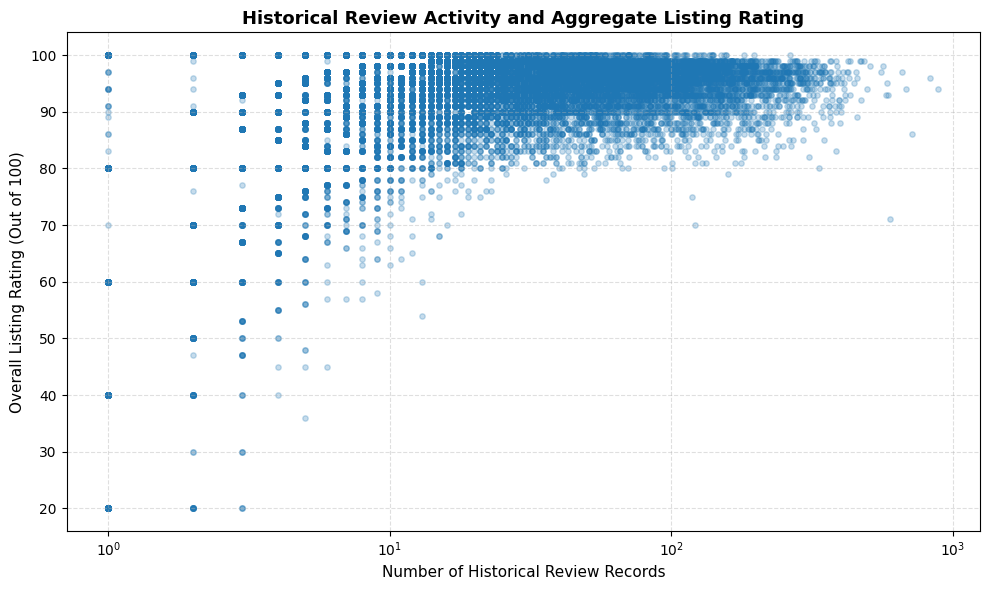

In [0]:

# VISUALISATION 6: Review activity versus aggregate listing rating.

# Select listings with available ratings.
rating_review = df.dropna(
    subset=["review_scores_rating"]
).copy()

# Take a sample for plotting efficiency.
rating_sample = rating_review.sample(
    n=min(30000, len(rating_review)),
    random_state=42
)

# Create the scatter plot.
plt.figure(figsize=(10, 6))

plt.scatter(
    rating_sample["review_count"],
    rating_sample["review_scores_rating"],
    alpha=0.25,
    s=15
)

# Use a symmetric logarithmic scale for review counts.
plt.xscale("symlog", linthresh=1)

# Add titles and labels.
plt.title(
    "Historical Review Activity and Aggregate Listing Rating",
    fontweight="bold"
)

plt.xlabel("Number of Historical Review Records")
plt.ylabel("Overall Listing Rating (Out of 100)")

plt.grid(
    linestyle="--",
    alpha=0.4
)

plt.tight_layout()
plt.show()


## 6. Hypothesis testing

Run each test on the appropriate within-city or listing-level sample. Report the test statistic, p-value, sample size and effect size where available. A conventional significance threshold of 0.05 is used, but p-values must not be interpreted alone.

In [0]:
# H1: Kruskal-Wallis test for price differences across room types, separately by city.
# Groups with fewer than 30 observations are excluded from the inferential test.
h1_rows = []

for city, city_data in df_price.groupby("city"):
    groups = []
    included_rooms = []

    for room_type, room_data in city_data.groupby("room_type"):
        values = room_data["price"].dropna().values
        if len(values) >= 30:
            groups.append(values)
            included_rooms.append(room_type)

    if len(groups) >= 2:
        h_stat, p_value = stats.kruskal(*groups)
        n_total = sum(len(group) for group in groups)
        k_groups = len(groups)

        # Epsilon-squared is an approximate effect-size measure for Kruskal-Wallis.
        epsilon_sq = max(0, (h_stat - k_groups + 1) / (n_total - k_groups))

        h1_rows.append({
            "city": city,
            "n": n_total,
            "groups_tested": ", ".join(included_rooms),
            "H_statistic": h_stat,
            "p_value": p_value,
            "epsilon_squared": epsilon_sq
        })

h1_results = pd.DataFrame(h1_rows).sort_values("p_value")
display(h1_results)

,city,n,groups_tested,H_statistic,p_value,epsilon_squared
1,Cape Town,19086,"Entire place, Hotel room, Private room, Shared...",2689.313267,0.000000e+00,0.140777
2,Hong Kong,7087,"Entire place, Hotel room, Private room, Shared...",1889.268455,0.000000e+00,0.266309
3,Istanbul,24517,"Entire place, Hotel room, Private room, Shared...",5308.339727,0.000000e+00,0.216430
4,Mexico City,20058,"Entire place, Hotel room, Private room, Shared...",6586.429648,0.000000e+00,0.328285
5,New York,36984,"Entire place, Hotel room, Private room, Shared...",15303.152212,0.000000e+00,0.413741
6,Paris,64628,"Entire place, Hotel room, Private room, Shared...",5339.005423,0.000000e+00,0.082570
7,Rio de Janeiro,26608,"Entire place, Hotel room, Private room, Shared...",4062.885306,0.000000e+00,0.152604
8,Rome,27641,"Entire place, Hotel room, Private room, Shared...",4243.480307,0.000000e+00,0.153435
9,Sydney,33630,"Entire place, Hotel room, Private room, Shared...",14359.646710,0.000000e+00,0.426951
0,Bangkok,19360,"Entire place, Hotel room, Private room, Shared...",932.982526,6.205262e-202,0.048046


In [0]:
# H2: Spearman correlation between accommodation capacity and advertised price by city.
h2_rows = []

for city, city_data in df_price.dropna(
    subset=["accommodates", "price"]
).groupby("city"):
    rho, p_value = stats.spearmanr(
        city_data["accommodates"],
        city_data["price"]
    )
    h2_rows.append({
        "city": city,
        "n": len(city_data),
        "spearman_rho": rho,
        "p_value": p_value
    })

h2_results = pd.DataFrame(h2_rows).sort_values("spearman_rho", ascending=False)
display(h2_results)

,city,n,spearman_rho,p_value
9,Sydney,33630,0.680045,0.0
1,Cape Town,19086,0.670576,0.0
4,Mexico City,20058,0.556760,0.0
5,New York,36984,0.553680,0.0
6,Paris,64628,0.529360,0.0
7,Rio de Janeiro,26608,0.517523,0.0
2,Hong Kong,7087,0.512937,0.0
3,Istanbul,24517,0.505954,0.0
8,Rome,27641,0.494042,0.0
0,Bangkok,19360,0.313449,0.0


In [0]:
# H3: Spearman correlation between review count and aggregate overall rating.
# Only listings with a non-missing overall rating are included.
h3_data = df.dropna(
    subset=["review_count", "review_scores_rating"]
).copy()

h3_rho, h3_p = stats.spearmanr(
    h3_data["review_count"],
    h3_data["review_scores_rating"]
)

h3_results = pd.DataFrame([{
    "n": len(h3_data),
    "spearman_rho": h3_rho,
    "p_value": h3_p
}])
display(h3_results)

,n,spearman_rho,p_value
0,188307,-0.204911,0.0


## 7. Interpretation and reporting

Use the following checklist when interpreting results:

- For H1, a significant Kruskal–Wallis result indicates that at least one room-type price distribution differs within that city. It does **not** identify which pairs differ. A post-hoc Dunn test with multiplicity correction would be needed for pairwise conclusions.
- For H2, a positive Spearman coefficient indicates that listings accommodating more guests tend to have higher advertised prices within that city. It does not prove that capacity causes higher prices.
- For H3, the sign and magnitude of Spearman's rho describe the monotonic association between review volume and aggregate rating. Review volume is not the same as occupancy or guest sentiment.
- Report medians and interquartile ranges because advertised prices are skewed and contain extreme values.
- Do not compare raw price levels between cities: the Listings table does not include a dedicated currency field.
- Explain that extreme values may influence means and visual scales. Retain valid observations unless a documented rule justifies exclusion; use robust summaries and sensitivity checks.

In [0]:
# Create compact tables for the report.
# City prices are deliberately labelled as local-currency amounts.
price_by_room = (
    df_price.groupby(["city", "room_type"])["price"]
    .agg(listings="count", median_price="median", q1=lambda x: x.quantile(.25),
         q3=lambda x: x.quantile(.75))
    .reset_index()
)
display(price_by_room.sort_values(["city", "median_price"], ascending=[True, False]))

# Review activity summary by city.
review_activity_by_city = (
    df.groupby("city")["review_count"]
    .agg(listings="count", median_reviews="median", mean_reviews="mean")
    .reset_index()
)
display(review_activity_by_city)

,city,room_type,listings,median_price,q1,q3
1,Bangkok,Hotel room,1019,1275.0,800.00,2200.0
0,Bangkok,Entire place,10623,1192.0,750.00,2000.0
2,Bangkok,Private room,6993,1000.0,700.00,1800.0
3,Bangkok,Shared room,725,450.0,350.00,650.0
5,Cape Town,Hotel room,306,1350.5,870.00,2510.5
4,Cape Town,Entire place,14150,1287.5,780.25,2633.0
6,Cape Town,Private room,4503,622.0,400.00,1100.0
7,Cape Town,Shared room,127,282.0,200.00,600.0
8,Hong Kong,Entire place,2589,690.0,409.00,1027.0
9,Hong Kong,Hotel room,180,450.0,251.00,823.5


,city,listings,median_reviews,mean_reviews
0,Bangkok,19361,1.0,14.686328
1,Cape Town,19086,3.0,15.840721
2,Hong Kong,7087,1.0,18.940031
3,Istanbul,24519,0.0,7.912762
4,Mexico City,20065,5.0,23.801844
5,New York,37012,4.0,22.904112
6,Paris,64690,5.0,18.762204
7,Rio de Janeiro,26615,2.0,12.146308
8,Rome,27647,8.0,40.270554
9,Sydney,33630,2.0,14.348855


### End of analysis